In [1]:
import pandas as pd
import numpy as np
import pickle
import glob
from scipy.stats import norm
from scipy.stats import gaussian_kde
import os

import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
from scipy.stats import gaussian_kde

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'
# import scipy.io as sio

In [33]:
def half_fft(y, t = None, dt = None):
    """
    Compute the one-sided FFT of a signal.

    Parameters:
        y (numpy.ndarray): The input signal in time domain.
        t (numpy.ndarray, optional): The time array corresponding to the signal. If not provided, `dt` must be specified.
        dt (float, optional): The time step (1/sample rate). If not provided, it will be calculated from `t`.

    Returns:
        tuple: A tuple containing:
            - y_fft (numpy.ndarray): The one-sided FFT of the input signal.
            - freq (numpy.ndarray): The corresponding frequency array.

    Notes:
        - If both `t` and `dt` are not provided, the function will return `None` and print an error message.
        - The FFT is normalized using the 'forward' norm, and the amplitudes are doubled for non-DC components.
    """
    
    if dt is None:
        try:
            dt = np.mean(np.diff(t))
        except:
            print('You must either provide an array of times or a dt (1/sample rate).')
            return None
    
    y_fft = np.fft.fft(y, norm = 'forward')
    freq = np.fft.fftfreq(len(y_fft), dt)

    fidx = freq>=0
    freq=freq[fidx]
    y_fft = y_fft[fidx]
    y_fft = np.abs(y_fft)
    y_fft[1:]*=2
    
    return y_fft, freq

In [2]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds
Num_Repeats = 30

In [20]:
filepath_model = glob.glob('./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/*.pickle')
filepath_degrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_degrees.pickle')
filepath_notdegrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_scaled.pickle')

out_path = './dataFolder/Figures/3_1DCompModel/STAFeatures/'
os.makedirs(out_path, exist_ok=True)

In [21]:
# instead of going through all data, make list of moth and unit IDs that you want to run this analysis for

moth_unit = [('m23', 'unit_1'),
             ('m29', 'unit_1'),
             ('m30', 'unit_1'),
             ('m31', 'unit_1'),
             ('m31', 'unit_2'),
             ('m31', 'unit_3')]

In [22]:
filepath = [f for f in filepath_model if name + '_' + unitID in f][0]

processing m23 and unit_1
processing m29 and unit_1
processing m30 and unit_1
processing m31 and unit_1
processing m31 and unit_2
processing m31 and unit_3


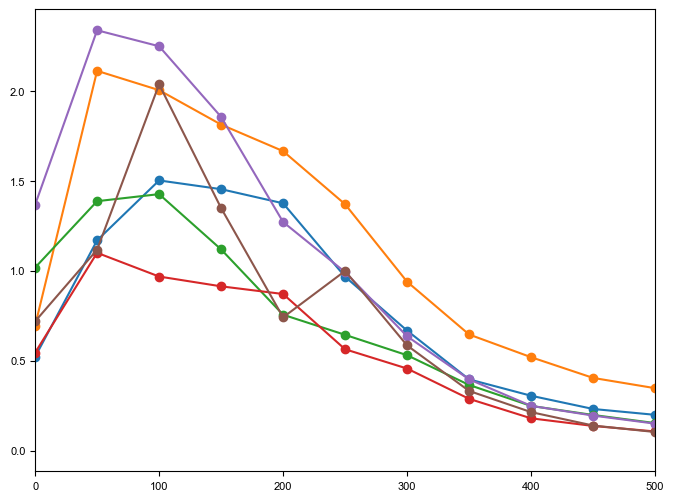

In [57]:
# read in all the data

fig_fft, ax_fft = plt.subplots(figsize=(8, 6))

for name, unitID in moth_unit:
    print(f'processing {name} and {unitID}')
    
    ########## get the correct timestamp files depending on whether we have degree or not #########################
    filename = [f for f in filepath_degrees if name in f]
    if not filename:
        filename = [f for f in filepath_notdegrees if name in f][0]
        with open(filename, "rb") as f:
            testout = pickle.load(f)
        WhiteNoise = testout[2]
        
    else:
        with open(filename[0], "rb") as f:
            testout = pickle.load(f)
        WhiteNoise = testout[2]

    
    ########## get the data files #########################  
    filename = [f for f in filepath_model if name + '_' + unitID in f][0]
    with open(filename, 'rb') as f:
                savedModel = pickle.load(f)
    
#     ste = savedModel[0]
    sta = savedModel[1]
    sta_error = savedModel[2]
#     prior_ensemble = savedModel[3]
#     prior_mean = savedModel[4]
#     prior_error = savedModel[5]
#     prior_std = savedModel[6]
#     mean_fire_rate = savedModel[7]
#     nld = savedModel[8]
#     n_ste = savedModel[9]
#     n_prior = savedModel[10]
#     bin_centers = savedModel[11]
#     bin_centers_fwdModel = savedModel[12]
#     nld_fwdModel = savedModel[13]
    
    ######## fft of STA #################################

    fft, freq = half_fft(y = sta[:-int(TimePost*Fs)], dt = 1/Fs)
    
    ######## plot fft ####################################
    ax_fft.plot(freq, fft, 'o-')
    ax_fft.set_xlim(0,500)
#     filename = out_path + name + '_' + unitID + '_STA.pdf'
#     fig_sta.savefig(filename)
#     ax_sta.cla()


In [98]:
fft_sta, freq_sta = half_fft(y = sta, dt = 1/Fs)

fft, freq = half_fft(y = WhiteNoise, dt = 1/Fs)

from scipy.signal import savgol_filter
fft_smoothened = savgol_filter(fft[1:], window_length=301, polyorder=3)

(0.0, 500.0)

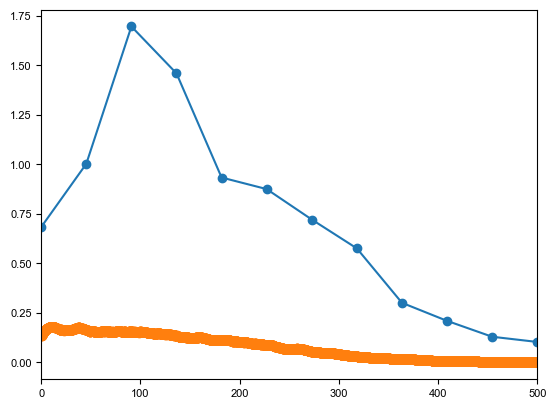

In [104]:
plt.plot(freq_sta, fft_sta, 'o-')
plt.plot(freq[1:], fft_smoothened, 'o-')
plt.xlim(0,500)
# plt.plot(freq, fft_sta[1:]/fft_smoothened)

In [94]:
len(fft_sta)

330

In [95]:
len(fft_smoothened)

150001